# The Mathematics of Decoding: Temperature, Truncation, Penalties, Search

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/teaching-nlp-notebooks-sampling/blob/main/02_sampling_mathematics.ipynb)

After a context, GPT-2 small has a score $z_i$ for each of its $|V| = 50{,}257$ tokens. A decoding rule is a map from these scores to a distribution $q$ over the next token, followed by a draw from $q$ or by a search. The rules in common use are built from three operations on $z$: a rescaling (temperature), a truncation (top-k, top-p, min-p) and a change of single scores (repetition penalty). Greedy decoding and beam search are searches: no token is drawn.

Run the two setup cells first; on the first run, GPT-2 small (548 MB) is downloaded. In each section, answer the question, read the derivation, run the check (on any mismatch, the cell stops at an `assert`), move the sliders, then open the answer. Logarithms are natural (nats) unless marked $\log_2$ (bits). Four prompts recur under short names: `AUSTEN` = `It is a truth universally acknowledged that`, `PEAKED` = `The Prime Minister of the United`, `FLAT` = `I went to the`, `BANK` = `The central bank decided to`.

In [1]:
# @title Setup: GPT-2 small and the decoding rules (run this cell first)
import functools, html, inspect, subprocess, sys, warnings

warnings.filterwarnings("ignore")
try:
    import transformers  # preinstalled in Colab
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display
from huggingface_hub.utils import logging as hub_logging
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
torch.set_grad_enabled(False)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Loading GPT-2 small; on the first run, 548 MB are downloaded ...")
tok = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval().to(DEVICE)
V = len(tok)  # 50,257 tokens

AUSTEN = "It is a truth universally acknowledged that"
PEAKED = "The Prime Minister of the United"
FLAT = "I went to the"
BANK = "The central bank decided to"
PROMPTS = [AUSTEN, PEAKED, FLAT, BANK]

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 9, "legend.frameon": False,
})


def forward(seqs):
    """GPT-2's scores at every position of each token list in `seqs` (all of one length), float64 on the CPU."""
    return model(torch.tensor(seqs, device=DEVICE)).logits.double().cpu()


@functools.lru_cache(maxsize=128)
def logits(text):
    """GPT-2's score z_i for every token i that may follow `text`."""
    z = forward([tok(text).input_ids])[0, -1].numpy()
    z.setflags(write=False)
    return z


def softmax(z, T=1.0):
    """Probabilities from the scores z at temperature T. T = 0 puts all mass on the largest score."""
    if T == 0:
        p = np.zeros(len(z))
        p[np.argmax(z)] = 1.0
        return p
    e = np.exp((np.asarray(z) - np.max(z)) / T)
    return e / e.sum()


def top_k_filter(p, k):
    """Keep the k likeliest tokens (ties at the boundary kept), rescale them to sum to 1."""
    q = np.where(p >= np.sort(p)[-k], p, 0.0)
    return q / q.sum()


def top_p_filter(p, top_p):
    """Keep the smallest set of likeliest tokens whose probabilities add up to at least top_p."""
    order = np.argsort(p)                      # least likely first
    drop = np.cumsum(p[order]) <= 1 - top_p    # the tail holding at most 1 - top_p
    drop[-1] = False                           # the likeliest token always stays
    q = p.copy()
    q[order[drop]] = 0.0
    return q / q.sum()


def min_p_filter(p, p_base):
    """Keep every token whose probability is at least p_base times the largest probability."""
    q = np.where(p >= p_base * p.max(), p, 0.0)
    return q / q.sum()


def penalise(z, seen, theta):
    """Repetition penalty: scores of tokens already in the text, divided by theta if positive, times theta if negative."""
    z = np.array(z)
    s = z[seen]
    z[seen] = np.where(s < 0, s * theta, s / theta)
    return z


def next_token_dist(z, T=0.0, k=0, top_p=1.0, min_p=0.0):
    """The distribution the next token is drawn from: temperature, then top-k, top-p, min-p (k = 0: no top-k)."""
    p = softmax(z, T)
    if k:
        p = top_k_filter(p, k)
    if top_p < 1:
        p = top_p_filter(p, top_p)
    if min_p > 0:
        p = min_p_filter(p, min_p)
    return p


def generate(text, n_tokens=30, T=0.0, k=0, top_p=1.0, min_p=0.0, theta=1.0, n=1, draw=0):
    """n continuations of `text`, token by token. Each is (tokens, GPT-2's probability at T = 1 of each token)."""
    rng = np.random.default_rng(draw)
    start = tok(text).input_ids
    seqs = [list(start) for _ in range(n)]
    probs = [[] for _ in range(n)]
    for _ in range(n_tokens):
        Z = forward(seqs)[:, -1].numpy()
        for s in range(n):
            z = penalise(Z[s], np.unique(seqs[s]), theta) if theta != 1 else Z[s]
            t = int(rng.choice(V, p=next_token_dist(z, T, k, top_p, min_p)))
            probs[s].append(softmax(Z[s])[t])
            seqs[s].append(t)
    out = []
    for seq, pr in zip(seqs, probs):
        new = seq[len(start):]
        end = new.index(tok.eos_token_id) + 1 if tok.eos_token_id in new else len(new)  # stop at <|endoftext|>
        out.append((new[:end], pr[:end]))
    return out


def word(i):
    """Token i as text, without GPT-2's leading space."""
    s = tok.decode([int(i)])
    return s.strip() or repr(s)


def shade(p):
    """Background colour for a token of probability p: white near 1, dark orange at 0.001 and below."""
    level = np.clip(-np.log10(max(p, 1e-12)) / 3, 0, 1)
    r, g, b, _ = plt.get_cmap("Oranges")(0.8 * level)
    return f"rgb({r * 255:.0f},{g * 255:.0f},{b * 255:.0f})"


def show_text(text, tokens, probs, label=""):
    """The prompt in grey, then each new token on a background set by GPT-2's probability of it."""
    spans = "".join(
        f'<span title="probability {p:.3g}" style="background:{shade(p)};color:#0b0b0b">'
        f'{html.escape(tok.decode([t])).replace(chr(10), "↵")}</span>'
        for t, p in zip(tokens, probs))
    head = f'<b style="color:#52514e">{html.escape(label)}</b> ' if label else ""
    display(HTML(
        f'<div style="font-family:Menlo,monospace;font-size:12px;line-height:1.8;background:#fff;'
        f'color:#0b0b0b;padding:4px 8px;margin:2px 0;border-left:3px solid {GREY}">'
        f'{head}<span style="color:#8a8983">{html.escape(text)}</span>{spans}</div>'))


def colour_key():
    cells = "".join(f'<span style="background:{shade(p)};color:#0b0b0b;padding:0 6px">{p:g}</span> '
                    for p in (1, 0.1, 0.01, 0.001))
    display(HTML(f'<div style="font-size:11px;color:#52514e;background:#fff;padding:2px 6px">'
                 f'background: GPT-2\'s probability of each new token at T = 1, before any rule: {cells}</div>'))


def sentences(text, n=3, n_tokens=30, label="", **rule):
    """Print n continuations of `text` under one decoding rule."""
    for tokens, probs in generate(text, n_tokens, n=n, **rule):
        show_text(text, tokens, probs, label)


def bars(ax, p, keep=None, n=20, color=BLUE, order=None, label=None):
    """Bar chart of the n likeliest tokens; tokens outside `keep` in grey."""
    top = np.argsort(-p)[:n] if order is None else order
    colours = [color if keep is None or keep[i] else GREY for i in top]
    ax.bar(np.arange(len(top)), p[top], width=0.7, color=colours, label=label)
    ax.set_xticks(np.arange(len(top)), [word(i) for i in top], rotation=55, ha="right")
    ax.set_ylabel("probability")
    ax.set_xlabel("next token")
    return top


def slider(lo, hi, step, value, name=""):
    kind = widgets.IntSlider if isinstance(step, int) else widgets.FloatSlider
    return kind(min=lo, max=hi, step=step, value=value, description=name, continuous_update=False)


def prompt_box(value=AUSTEN):
    """A text box with the four prompts as suggestions; any other text works too (press Enter)."""
    return widgets.Combobox(value=value, options=PROMPTS, ensure_option=False, description="prompt",
                            continuous_update=False, layout=widgets.Layout(width="90%"))


def explore(f, **controls):
    """Sliders for the arguments of f; the output is redrawn when a slider is released."""
    missing = set(inspect.signature(f).parameters) - set(controls)
    assert not missing, f"no control for {missing}"
    @functools.wraps(f)
    def g(**kwargs):
        if "prompt" in kwargs:
            kwargs["prompt"] = kwargs["prompt"].strip() or AUSTEN  # an empty box falls back to the Austen prompt
        f(**kwargs)
    widgets.interact(g, **controls)


print(f"GPT-2 small loaded: {sum(x.numel() for x in model.parameters()):,} parameters, {V:,} tokens.")

Loading GPT-2 small; on the first run, 548 MB are downloaded ...


GPT-2 small loaded: 124,439,808 parameters, 50,257 tokens.


In [2]:
# @title Charts for the sections below (run this cell)
PROMPT_COLOURS = {PEAKED: BLUE, AUSTEN: ORANGE, FLAT: AQUA}


def entropy(p):
    """Entropy in nats."""
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def log_softmax(z):
    z = np.asarray(z)
    return z - z.max() - np.log(np.exp(z - z.max()).sum())


def log_softmax_steps(prompt, tokens):
    """log p of each token of a continuation, from one forward pass over prompt and continuation."""
    ids = tok(prompt).input_ids
    L = torch.log_softmax(forward([ids + list(tokens)])[0], -1).numpy()
    return np.array([L[len(ids) - 1 + t, tok_id] for t, tok_id in enumerate(tokens)])


def beam_search(text, B, n_tokens=20):
    """Beam search of width B: the B partial continuations with the largest log P, extended token by token."""
    start = tok(text).input_ids
    beams = [(start, 0.0)]                                                     # (tokens, log P)
    for _ in range(n_tokens):
        L = torch.log_softmax(forward([s for s, _ in beams])[:, -1], -1).numpy()
        L = L + np.array([[lp] for _, lp in beams])                            # log P of every extension
        best = np.argsort(L, axis=None)[::-1][:B]                              # the B largest of B x 50,257
        beams = [(beams[r][0] + [int(c)], L[r, c]) for r, c in zip(*np.unravel_index(best, L.shape))]
    return beams[0][0][len(start):], float(beams[0][1])


def show_surprise(prompt=AUSTEN, T=0.0, draw=0, n_tokens=20):
    rows = [("greedy", generate(prompt, n_tokens)[0])]
    if T > 0:
        rows.append((f"drawn at T = {T:g}", generate(prompt, n_tokens, T=T, draw=draw)[0]))
    fig, axes = plt.subplots(len(rows), 1, figsize=(9, 2.4 * len(rows)), squeeze=False)
    for ax, (name, (tokens, probs)) in zip(axes[:, 0], rows):
        s = -np.log2(probs)
        ax.bar(np.arange(len(s)), s, width=0.7, color=BLUE)
        ax.set_xticks(np.arange(len(s)), [word(t) for t in tokens], rotation=55, ha="right")
        ax.set_ylabel("surprise, bits")
        ax.set_title(f"{name}: log P = {np.log(probs).sum():.2f} nats, {np.log(probs).mean():.3f} per token")
    plt.tight_layout()
    plt.show()


def show_entropy(T=0.0):
    Ts = np.linspace(0.02, 3, 150)
    fig, ax = plt.subplots(figsize=(7, 3))
    for prompt, c in PROMPT_COLOURS.items():
        z = logits(prompt)
        H = [entropy(softmax(z, t)) / np.log(2) for t in Ts]
        ax.plot(Ts, H, color=c, lw=2, label=f'"{prompt}"')
        ax.plot([T], [entropy(softmax(z, T)) / np.log(2)], "o", color=c, ms=8)
    ax.axhline(np.log2(V), color=INK, ls="--", lw=1)
    ax.text(0.05, np.log2(V) - 0.4, f"log2 |V| = {np.log2(V):.2f} bits", ha="left", va="top", color=INK)
    ax.set_xlabel("temperature T")
    ax.set_ylabel("entropy H, bits")
    ax.set_title(f"entropy of the next token against T; dots at T = {T:g}")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22))
    plt.show()


def show_top_k_mass(k=10, T=0.0):
    ks = np.arange(1, V + 1)
    fig, ax = plt.subplots(figsize=(7, 3))
    for prompt, c in PROMPT_COLOURS.items():
        M = np.cumsum(np.sort(softmax(logits(prompt), T))[::-1])
        ax.plot(ks, M, color=c, lw=2, label=f'"{prompt}": M = {M[k - 1]:.3f}, KL to p(T) = {-np.log(M[k - 1]):.3f}')
    ax.axvline(k, color=INK, ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("k (log scale)")
    ax.set_ylabel("kept mass M_k")
    ax.set_title(f"mass of the k likeliest tokens at T = {T:g}; dashed line at k = {k}")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22))
    plt.show()


def show_nucleus(pi=0.9, T=0.0):
    ranks = np.arange(1, V + 1)
    fig, ax = plt.subplots(figsize=(7, 3))
    for prompt, c in PROMPT_COLOURS.items():
        p = softmax(logits(prompt), T)
        cum = np.cumsum(np.sort(p)[::-1])
        k = int((top_p_filter(p, pi) > 0).sum())
        ax.plot(ranks, cum, color=c, lw=2, label=f'"{prompt}": {k:,} tokens, KL to p(T) = {-np.log(cum[k - 1]):.3f}')
        ax.plot([k], [cum[k - 1]], "o", color=c, ms=8)
    ax.axhline(pi, color=INK, ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("rank of the token (log scale)")
    ax.set_ylabel("cumulative probability")
    ax.set_title(f"nucleus at π = {pi:g}, T = {T:g}; bound -log π = {-np.log(pi):.3f} nats")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22))
    plt.show()


def min_p_bound(p, p_base):
    """The bound 1 + (1 - p_max) / (p_base p_max) on the number of tokens kept under min-p."""
    return 1 + (1 - p.max()) / (p_base * p.max())


def show_min_p(p_base=0.1, T=0.0):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    for ax, prompt in zip(axes, (PEAKED, FLAT)):
        p = softmax(logits(prompt), T)
        q = min_p_filter(p, p_base)
        bars(ax, p, keep=q > 0, n=18)
        ax.axhline(p_base * p.max(), color=ORANGE, lw=1.5)
        ax.set_title(f'"{prompt}"\n|S| = {int((q > 0).sum())}, bound {min_p_bound(p, p_base):.1f}; orange line p_base p_max')
    plt.tight_layout()
    plt.show()


def show_penalty(prompt=AUSTEN, theta=1.2, n_tokens=40):
    colour_key()
    for th in sorted({1.0, theta}):
        tokens, probs = generate(prompt, n_tokens, theta=th)[0]
        show_text(prompt, tokens, probs, label=f"greedy, θ = {th:g}, {len(set(tokens))} distinct tokens of {len(tokens)}")


def show_beam(prompt=AUSTEN, B=1, n_tokens=20):
    colour_key()
    for b in sorted({1, B}):
        tokens, lp = beam_search(prompt, b, n_tokens)
        show_text(prompt, tokens, np.exp(log_softmax_steps(prompt, tokens)), label=f"B = {b}, log P = {lp:.2f}")


def sample_stats(prompt, T, pi=1.0, draw=0, n=5, n_tokens=30):
    """Mean log p per token, and mean share of distinct tokens per continuation, over n continuations."""
    out = generate(prompt, n_tokens, T=T, top_p=pi, n=n, draw=draw)
    logp = np.mean([np.log(x) for _, probs in out for x in probs])
    distinct = np.mean([len(set(s)) / len(s) for s, _ in out])
    return logp, distinct


@functools.lru_cache(maxsize=8)
def reference_points(prompt):
    settings = [("greedy", 0.0, 1.0), ("T = 0.7", 0.7, 1.0), ("T = 1", 1.0, 1.0),
                ("T = 1.5", 1.5, 1.0), ("T = 1, π = 0.9", 1.0, 0.9)]  # T > 0: five random draws per setting
    return [(name, *sample_stats(prompt, T, pi)) for name, T, pi in settings]


def show_tradeoff(prompt=AUSTEN, T=0.0, pi=1.0, draw=0):
    fig, ax = plt.subplots(figsize=(7, 3.2))
    refs = reference_points(prompt)
    offsets = {"greedy": (8, -14), "T = 0.7": (8, -14), "T = 1": (-34, 8), "T = 1.5": (8, 8), "T = 1, π = 0.9": (0, 8)}
    for name, lp, d in refs:
        ax.plot(lp, d, "o", color=BLUE, ms=8)
        ax.annotate(name, (lp, d), textcoords="offset points", xytext=offsets[name], color=INK)
    lp, d = sample_stats(prompt, T, pi, draw)
    ax.plot(lp, d, "*", color=ORANGE, ms=16, label=f"slider setting: T = {T:g}, π = {pi:g}")
    ax.set_xlabel("mean log p per token, nats (GPT-2 at T = 1)")
    ax.set_ylabel("distinct tokens per continuation")
    ax.margins(x=0.15, y=0.15)
    ax.set_title(f'five continuations of 30 tokens after "{prompt}"')
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2))
    plt.show()
    for name, lp_r, d_r in refs:
        print(f"{name:16s} mean log p {lp_r:7.3f}   distinct share {d_r:.3f}")
    print(f"{'slider setting':16s} mean log p {lp:7.3f}   distinct share {d:.3f}")

## 1. A Sentence's Probability Is the Product of Its Next-Token Probabilities

After a context $c$, the probability of token $i$ is the softmax of the scores,
$$p_i = \frac{e^{z_i}}{\sum_{j \in V} e^{z_j}}.$$
A continuation $w_1, \dots, w_n$ has probability
$$P(w_1, \dots, w_n \mid c) = \prod_{t=1}^{n} p(w_t \mid c, w_{<t}), \qquad \log P = \sum_{t=1}^{n} \log p(w_t \mid c, w_{<t}).$$

**Derivation.** By the definition of conditional probability, $P(A, B) = P(A)\,P(B \mid A)$. Applied $n - 1$ times to $(w_1, \dots, w_n)$, it gives the product. The surprise of token $t$ is $-\log_2 p(w_t \mid c, w_{<t})$ bits, and $-\log_2 P$ is the sum of the surprises.

**Check.** One forward pass of GPT-2 over the whole sequence gives every factor of $\log P$ at once, since the score at position $t$ depends on the tokens up to $t$ only (the causal mask). The sum over that one pass equals the sum of the 20 factors computed step by step.

**Question.** Which continuation of the Austen prompt has the larger $\log P$ per token: the greedy one, or one drawn at $T = 1$?

In [3]:
tokens, probs = generate(AUSTEN, 20)[0]                      # greedy, 20 tokens, one forward pass per step
step_by_step = np.log(probs).sum()
one_pass = log_softmax_steps(AUSTEN, tokens).sum()            # all 20 factors from one forward pass
print(f"log P step by step: {step_by_step:.6f}   in one pass: {one_pass:.6f}")
assert np.isclose(step_by_step, one_pass, atol=1e-4)

log P step by step: -27.766498   in one pass: -27.766503


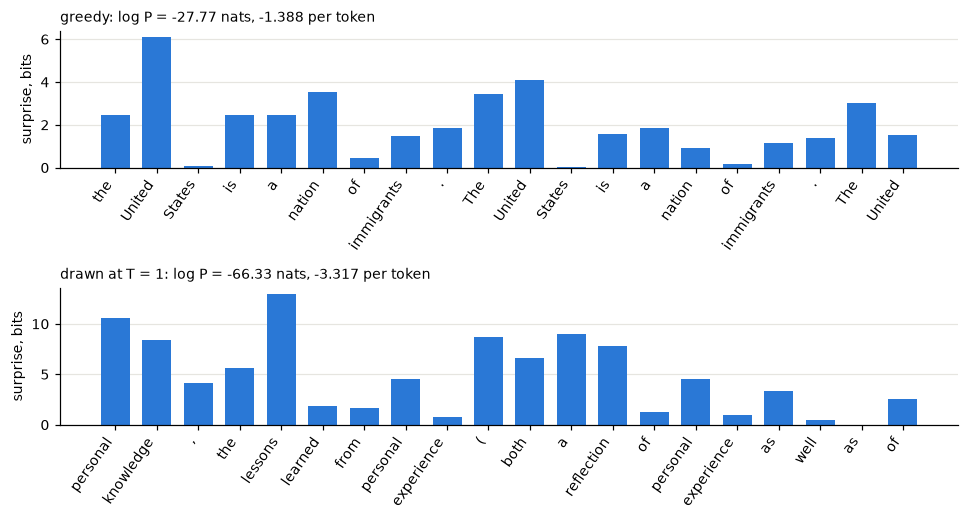

In [4]:
show_surprise(AUSTEN, T=1.0)  # T > 0: one random draw beside the greedy continuation

In [5]:
explore(show_surprise, prompt=prompt_box(AUSTEN), T=slider(0.0, 2.0, 0.1, 0.0), draw=slider(0, 9, 1, 0),
        n_tokens=slider(10, 40, 10, 20))

<details><summary><b>Answer</b></summary>

The greedy one, in this draw: $-1.388$ nats per token ($\log P = -27.77$ over 20 tokens), against $-3.317$ for the continuation drawn at $T = 1$ ($\log P = -66.33$). At one step the comparison is true in expectation: a token drawn from $p$ has expected log-probability $\mathbb{E}_p[\log p] = -H(p)$, at most $\log p_{\max}$, the log-probability of the greedy token; after the Austen prompt, $-6.38$ against $\log 0.182 = -1.70$. Over 20 tokens the factors are taken in different contexts, and the comparison rests on one draw. The greedy product over a whole sentence can be beaten by another path, as in the two-step tree of section 8.

</details>

## 2. Entropy Grows With Temperature

With temperature $T > 0$, write $p^{(T)}$ for
$$p^{(T)}_i = \frac{e^{z_i/T}}{\sum_{j} e^{z_j/T}},$$
and $p = p^{(1)}$ for GPT-2's own distribution.

**Ranking.** $p^{(T)}_i / p^{(T)}_j = e^{(z_i - z_j)/T}$ is above 1 exactly when $z_i > z_j$, at every $T$.

**Limits.** Let $m$ be the unique token with the largest score. For $i \ne m$, $p^{(T)}_i / p^{(T)}_m = e^{(z_i - z_m)/T} \to 0$ as $T \to 0^+$, so $p^{(T)} \to e_m$, the vector with a 1 at $m$: greedy decoding. As $T \to \infty$, $e^{z_i/T} \to 1$ for every $i$, so $p^{(T)}_i \to 1/|V|$.

**Entropy.** In this derivation $p$ stands for $p^{(T)}$. Write $\beta = 1/T$ and $Z(\beta) = \sum_j e^{\beta z_j}$, so $p_i = e^{\beta z_i}/Z$, $\log p_i = \beta z_i - \log Z$ and
$$H = -\sum_i p_i \log p_i = \log Z - \beta\, \mathbb{E}_p[z].$$
Differentiating, $\frac{d}{d\beta} \log Z = \frac{1}{Z} \sum_j z_j e^{\beta z_j} = \mathbb{E}_p[z]$ and $\frac{dp_i}{d\beta} = p_i\,(z_i - \mathbb{E}_p[z])$, so $\frac{d}{d\beta} \mathbb{E}_p[z] = \sum_i z_i\, p_i\, (z_i - \mathbb{E}_p[z]) = \mathrm{Var}_p(z)$. Then
$$\frac{dH}{d\beta} = \mathbb{E}_p[z] - \mathbb{E}_p[z] - \beta\, \mathrm{Var}_p(z) = -\beta\, \mathrm{Var}_p(z), \qquad \frac{dH}{dT} = \frac{dH}{d\beta} \cdot \Big(-\frac{1}{T^2}\Big) = \frac{\mathrm{Var}_p(z)}{T^3} \ \ge\ 0.$$

**Question.** Is there a prompt and a temperature at which the entropy falls when $T$ rises?

In [6]:
z = logits(AUSTEN)
assert np.argmax(softmax(z, 0.01)) == np.argmax(z) and softmax(z, 0.01).max() > 1 - 1e-12   # T -> 0: greedy
assert np.allclose(softmax(z, 1e6), 1 / V, rtol=1e-3)                                       # T -> infinity: uniform
h = 1e-4
for T in (0.7, 1.0, 1.5):  # T > 0: points on the curve H(T), no sampling
    p = softmax(z, T)
    var = (p * (z - (p * z).sum()) ** 2).sum()
    slope = (entropy(softmax(z, T + h)) - entropy(softmax(z, T - h))) / (2 * h)
    print(f"T = {T}: H = {entropy(p) / np.log(2):5.2f} bits;  dH/dT in nats per unit of T: "
          f"finite difference {slope:.5f}, Var(z)/T^3 = {var / T**3:.5f}")
    assert np.isclose(slope, var / T**3, rtol=1e-4)

T = 0.7: H =  3.61 bits;  dH/dT in nats per unit of T: finite difference 12.31490, Var(z)/T^3 = 12.31490
T = 1.0: H =  9.20 bits;  dH/dT in nats per unit of T: finite difference 10.60145, Var(z)/T^3 = 10.60145
T = 1.5: H = 13.20 bits;  dH/dT in nats per unit of T: finite difference 2.43686, Var(z)/T^3 = 2.43686


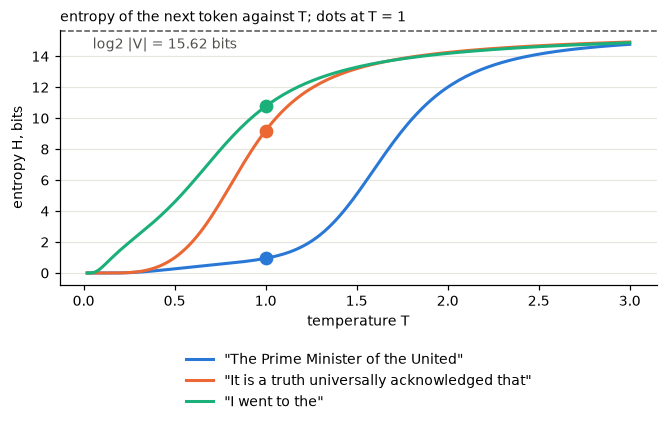

In [7]:
show_entropy(T=1.0)  # T > 0: position of the dots, no sampling

In [8]:
explore(show_entropy, T=slider(0.0, 2.0, 0.1, 0.0))

<details><summary><b>Answer</b></summary>

No. $dH/dT = \mathrm{Var}_p(z)/T^3$, and a variance is never negative; it is zero only when all scores are equal, and then $H = \log |V|$ at every $T$. After the Austen prompt, $H$ is 3.61 bits at $T = 0.7$, 9.20 at $T = 1$ and 13.20 at $T = 1.5$, below the maximum $\log_2 50{,}257 = 15.62$ bits.

</details>

## 3. Truncation: KL Divergence $-\log M$, Total Variation $1 - M$

Top-k, top-p and min-p are truncations, applied after temperature. In sections 3 to 6, $p$ is the distribution that is truncated, $p^{(T)}$ when a temperature is set, and every identity and bound is relative to it. Under each truncation, a set $S \subseteq V$ of mass $M = \sum_{i \in S} p_i$ is kept and rescaled:
$$q_i = \frac{p_i}{M} \ \ (i \in S), \qquad q_i = 0 \ \ (i \notin S).$$

**Kullback–Leibler divergence.** On $S$, $q_i/p_i = 1/M$, so
$$\mathrm{KL}(q \parallel p) = \sum_{i \in S} q_i \log \frac{q_i}{p_i} = \log\frac{1}{M} \sum_{i \in S} q_i = -\log M.$$

**Total variation.** On $S$, $q_i = p_i/M \ge p_i$ since $M \le 1$, so $\sum_{i \in S} |q_i - p_i| = \sum_{i \in S} (q_i - p_i) = 1 - M$; off $S$, $\sum_{i \notin S} |0 - p_i| = 1 - M$. Hence
$$\mathrm{TV}(p, q) = \frac12 \sum_i |p_i - q_i| = 1 - M.$$

In the other direction, $\mathrm{KL}(p \parallel q) = \infty$ whenever $M < 1$: $p$ has mass on tokens of probability zero under $q$. Relative to GPT-2's own distribution $p^{(1)}$, temperature followed by a truncation is further away: at $T = 0.7$, top-p at 0.9 after the Austen prompt gives $\mathrm{KL}(q \parallel p^{(1)}) = 0.925$ nats, against $-\log M = 0.105$ relative to $p^{(0.7)}$.

**Question.** A truncation cuts tokens of total probability 0.1. How far is $q$ from $p$ in nats, and in total variation?

In [9]:
p = softmax(logits(FLAT))
for name, q in [("top-k, k = 10", top_k_filter(p, 10)), ("top-p, π = 0.9", top_p_filter(p, 0.9)),
                ("min-p, 0.1", min_p_filter(p, 0.1))]:
    S = q > 0
    M = p[S].sum()
    kl = (q[S] * np.log(q[S] / p[S])).sum()
    tv = 0.5 * np.abs(p - q).sum()
    print(f"{name:15s} |S| = {S.sum():5,d}   M = {M:.4f}   KL = {kl:.4f}, -log M = {-np.log(M):.4f}   TV = {tv:.4f}, 1 - M = {1 - M:.4f}")
    assert np.isclose(kl, -np.log(M)) and np.isclose(tv, 1 - M)
z = logits(AUSTEN)
p1, q = softmax(z), top_p_filter(softmax(z, 0.7), 0.9)  # T > 0: temperature before truncation, no sampling
S = q > 0
print(f"Austen, T = 0.7, top-p 0.9: KL to p(0.7) = {-np.log(softmax(z, 0.7)[S].sum()):.3f}, "
      f"KL to p(1) = {(q[S] * np.log(q[S] / p1[S])).sum():.3f} nats")

top-k, k = 10   |S| =    10   M = 0.1665   KL = 1.7925, -log M = 1.7925   TV = 0.8335, 1 - M = 0.8335
top-p, π = 0.9  |S| = 4,797   M = 0.9000   KL = 0.1053, -log M = 0.1053   TV = 0.1000, 1 - M = 0.1000
min-p, 0.1      |S| =    30   M = 0.2705   KL = 1.3074, -log M = 1.3074   TV = 0.7295, 1 - M = 0.7295
Austen, T = 0.7, top-p 0.9: KL to p(0.7) = 0.105, KL to p(1) = 0.925 nats


<details><summary><b>Answer</b></summary>

$-\log 0.9 = 0.105$ nats and $1 - 0.9 = 0.1$, after every prompt and under every truncation rule: only the cut mass enters.

</details>

## 4. Top-k: The Kept Mass Depends on the Prompt

$S_k$ is the set of the $k$ tokens with the largest $p_i$, $M_k = \sum_{i \in S_k} p_i$, and $\mathrm{KL}(q \parallel p) = -\log M_k$.

**Bound over prompts.** The $k$ largest of $|V|$ probabilities that add up to 1 have a mean of at least $1/|V|$, so $M_k \ge k/|V|$ and $\mathrm{KL}(q \parallel p) \le \log(|V|/k)$ after every prompt: 8.52 nats at $k = 10$, reached when all tokens are equally likely. The top-p bound of section 5, $-\log \pi$, depends on the chosen $\pi$ alone; the top-k bound depends on the size of the vocabulary.

**$S_k$ is the same at every temperature.** $p^{(T)}_i > p^{(T)}_j$ exactly when $z_i > z_j$ (section 2), so the $k$ largest are the same tokens at every $T > 0$; the kept mass $M_k$ and the rescaled $q$ depend on $T$.

**Question.** At $k = 10$ and $T = 1$, how large is $\mathrm{KL}(q \parallel p)$ after the peaked prompt `The Prime Minister of the United`, and after the flat prompt `I went to the`?

In [10]:
for prompt in (PEAKED, FLAT):
    M = np.sort(softmax(logits(prompt)))[::-1][:10].sum()
    print(f'"{prompt}": M_10 = {M:.3f}, KL = -log M_10 = {-np.log(M):.3f} nats, bound log(|V|/10) = {np.log(V / 10):.2f}')
    assert M >= 10 / V
z = logits(AUSTEN)
kept = [set(np.flatnonzero(top_k_filter(softmax(z, T), 10))) for T in (0.7, 1.0, 1.5)]  # T > 0: no sampling
assert kept[0] == kept[1] == kept[2]
print("the same 10 tokens at T = 0.7, 1, 1.5:", [word(i) for i in sorted(kept[0], key=lambda i: -z[i])])

"The Prime Minister of the United": M_10 = 0.995, KL = -log M_10 = 0.005 nats, bound log(|V|/10) = 8.52
"I went to the": M_10 = 0.167, KL = -log M_10 = 1.792 nats, bound log(|V|/10) = 8.52
the same 10 tokens at T = 0.7, 1, 1.5: ['the', 'there', 'a', 'we', 'in', ',', 'all', 'it', 'our', 'many']


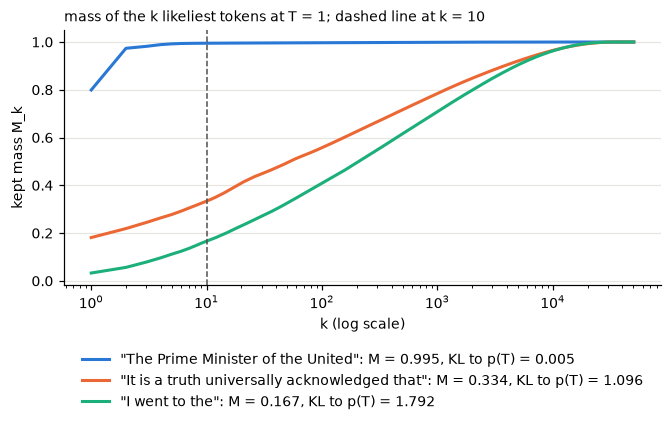

In [11]:
show_top_k_mass(k=10, T=1.0)  # T > 0: kept mass of the model's own distribution, no sampling

In [12]:
explore(show_top_k_mass, k=slider(1, 1000, 1, 10), T=slider(0.0, 2.0, 0.1, 0.0))

<details><summary><b>Answer</b></summary>

After the peaked prompt, $M_{10} = 0.995$ and $\mathrm{KL} = 0.005$ nats; after the flat prompt, $M_{10} = 0.167$ and $\mathrm{KL} = 1.792$ nats, both below the bound of 8.52. At $k = 10$ the cut mass is 0.5 per cent of the probability after one prompt and 83 per cent after the other.

</details>

## 5. Top-p: KL Divergence at Most $-\log \pi$

Write $\pi$ for the top-p threshold (Holtzman et al., 2020, call it $p$). Sort the probabilities, $p_{(1)} \ge p_{(2)} \ge \dots$, and keep the first
$$k^*(\pi) = \min\Big\{k : \sum_{j=1}^{k} p_{(j)} \ge \pi\Big\}$$
tokens. By construction $M \ge \pi$, so, after every prompt,
$$\mathrm{KL}(q \parallel p) = -\log M \le -\log \pi, \qquad \mathrm{TV}(p, q) = 1 - M \le 1 - \pi.$$
At $\pi = 0.9$: at most 0.105 nats.

**The nucleus grows with temperature.** Fix $k$, sort the scores $z_{(1)} \ge z_{(2)} \ge \dots$, and write the top-$k$ mass of $p^{(T)}$ as $1/(1 + R)$ with
$$R(\beta) = \frac{\sum_{j > k} e^{\beta z_{(j)}}}{\sum_{i \le k} e^{\beta z_{(i)}}}, \qquad \frac{d \log R}{d\beta} = \mathbb{E}\big[z \mid \text{rest}\big] - \mathbb{E}\big[z \mid \text{top } k\big] \ \le\ 0,$$
where each expectation is under $p^{(T)}$ restricted to its set, and every score in the rest is at most every score in the top $k$. So $R$ grows with $T$, the top-$k$ mass falls for every $k$, and $k^*(\pi)$ is non-decreasing in $T$.

**Question.** At $\pi = 0.9$ and $T = 1$, how many tokens are in the nucleus after the peaked and after the flat prompt? Which bound on KL is valid after both?

In [13]:
for prompt in (PEAKED, FLAT):
    p = softmax(logits(prompt))
    S = top_p_filter(p, 0.9) > 0
    print(f'"{prompt}": {S.sum():,} tokens, M = {p[S].sum():.3f}, KL = {-np.log(p[S].sum()):.3f} <= {-np.log(0.9):.3f}')
    assert p[S].sum() >= 0.9
z = logits(AUSTEN)
Ts = np.round(np.arange(0.2, 2.01, 0.1), 1)  # T > 0: nucleus sizes, no sampling
sizes = [int((top_p_filter(softmax(z, T), 0.9) > 0).sum()) for T in Ts]
print("nucleus at π = 0.9 after the Austen prompt:", dict(zip(Ts.tolist(), sizes)))
assert all(a <= b for a, b in zip(sizes, sizes[1:]))

"The Prime Minister of the United": 2 tokens, M = 0.974, KL = 0.027 <= 0.105
"I went to the": 4,797 tokens, M = 0.900, KL = 0.105 <= 0.105
nucleus at π = 0.9 after the Austen prompt: {0.2: 1, 0.3: 1, 0.4: 1, 0.5: 2, 0.6: 8, 0.7: 42, 0.8: 325, 0.9: 1447, 1.0: 3784, 1.1: 6655, 1.2: 9400, 1.3: 11817, 1.4: 13899, 1.5: 15670, 1.6: 17206, 1.7: 18541, 1.8: 19711, 1.9: 20754, 2.0: 21692}


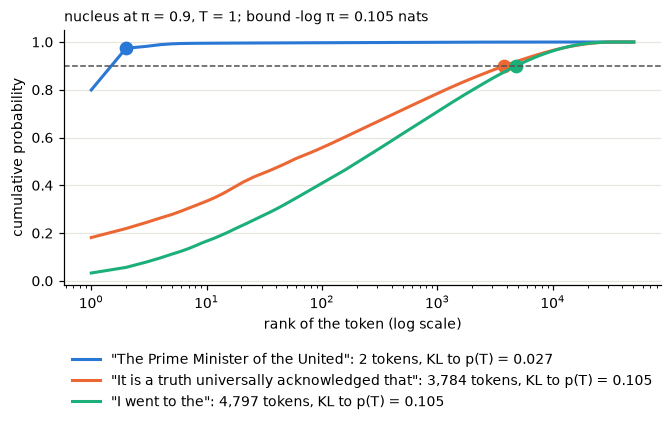

In [14]:
show_nucleus(pi=0.9, T=1.0)  # T > 0: nucleus of the model's own distribution, no sampling

In [15]:
explore(show_nucleus, pi=slider(0.05, 1.0, 0.05, 0.9), T=slider(0.0, 2.0, 0.1, 0.0))

<details><summary><b>Answer</b></summary>

2 tokens after `The Prime Minister of the United` and 4,797 after `I went to the`; $\mathrm{KL} \le -\log 0.9 = 0.105$ nats is valid for both. After the Austen prompt, the nucleus has 42 tokens at $T = 0.7$, 3,784 at $T = 1$ and 15,670 at $T = 1.5$.

</details>

## 6. Min-p: At Most $1 + (1 - p_{\max})/(p_{\text{base}}\, p_{\max})$ Tokens

Under min-p (Nguyen et al., 2024), a token is kept when its probability is at least a fraction $p_{\text{base}}$ of the largest:
$$S = \{\, i : p_i \ge p_{\text{base}}\, p_{\max} \,\}.$$

**Size bound.** The likeliest token is in $S$ and has $p_{\max}$. Every other kept token has at least $p_{\text{base}}\, p_{\max}$, and together they have at most $1 - p_{\max}$, so $(|S| - 1)\, p_{\text{base}}\, p_{\max} \le 1 - p_{\max}$:
$$|S| \ \le\ 1 + \frac{1 - p_{\max}}{p_{\text{base}}\, p_{\max}} \ \le\ \frac{1}{p_{\text{base}}\, p_{\max}}.$$
The second inequality is $p_{\max}\,(1 - p_{\text{base}}) \ge 0$, rearranged.

**Under temperature.** $p^{(T)}_i / p^{(T)}_{\max} = e^{(z_i - z_{\max})/T}$, so the rule is a threshold on the scores,
$$z_i \ \ge\ z_{\max} + T \log p_{\text{base}}.$$
With $\log p_{\text{base}} < 0$, the threshold falls as $T$ rises, and $S$ grows. In Hugging Face `transformers`, temperature is applied before min-p. Nguyen et al. recommend $p_{\text{base}}$ between 0.05 and 0.1.

**Question.** With $p_{\text{base}} = 0.1$, how many tokens can be kept at most after a context whose likeliest token has probability 0.5?

In [16]:
for prompt in (PEAKED, FLAT):
    z = logits(prompt)
    for T in (0.7, 1.0, 1.5):  # T > 0: kept sets, no sampling
        p = softmax(z, T)
        S = min_p_filter(p, 0.1) > 0
        S_scores = z >= z.max() + T * np.log(0.1)
        print(f'"{prompt}", T = {T}: |S| = {S.sum():3d}, bound {min_p_bound(p, 0.1):7.1f}, weaker bound {1 / (0.1 * p.max()):7.1f}')
        assert (S == S_scores).all() and S.sum() <= min_p_bound(p, 0.1) <= 1 / (0.1 * p.max())

"The Prime Minister of the United", T = 0.7: |S| =   2, bound     2.2, weaker bound    11.2
"The Prime Minister of the United", T = 1.0: |S| =   2, bound     3.5, weaker bound    12.5
"The Prime Minister of the United", T = 1.5: |S| =   2, bound    11.1, weaker bound    20.1
"I went to the", T = 0.7: |S| =  16, bound    76.8, weaker bound    85.8
"I went to the", T = 1.0: |S| =  30, bound   293.0, weaker bound   302.0
"I went to the", T = 1.5: |S| = 112, bound  1645.2, weaker bound  1654.2


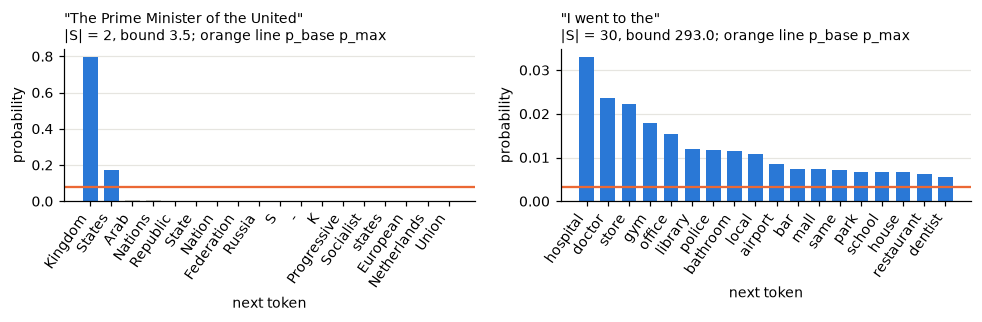

In [17]:
show_min_p(p_base=0.1, T=1.0)  # T > 0: kept sets of the model's own distribution, no sampling

In [18]:
explore(show_min_p, p_base=slider(0.01, 0.5, 0.01, 0.1), T=slider(0.0, 2.0, 0.1, 0.0))

<details><summary><b>Answer</b></summary>

$1 + 0.5/(0.1 \cdot 0.5) = 11$, and under a softmax at most 10: 11 would need ten tokens at exactly 0.05 and probability 0 for all other tokens, and every softmax probability is positive. The weaker bound $1/(p_{\text{base}}\, p_{\max})$ gives 20. After the peaked prompt, 2 tokens are kept at $T = 0.7$, 1 and 1.5, against bounds of 2.2, 3.5 and 11.1; after the flat prompt 16, 30 and 112, against bounds of 76.8, 293.0 and 1,645.2.

</details>

## 7. The Repetition Penalty Depends on the Offset of the Scores

For every token $i$ already in the text, Hugging Face `transformers` replace the score by
$$z_i' = \begin{cases} z_i / \theta, & z_i > 0, \\ \theta\, z_i, & z_i \le 0, \end{cases} \qquad \theta > 1.$$
Keskar et al. (2019) divided the scores of the tokens generated so far by $\theta$ and reported $\theta \approx 1.2$ with greedy decoding. For a negative score, a division would raise it; Hugging Face multiplies negative scores by $\theta$, so that both cases give $z_i' \le z_i$, and includes the prompt's tokens (with the parameter `prompt_ignore_length` of `RepetitionPenaltyLogitsProcessor`, the prompt is left out).

**Effect.** Let $A$ be the set of tokens in the text. For $i \in A$ and $j \notin A$, $p'_i/p'_j = e^{z'_i - z_j} \le e^{z_i - z_j} = p_i/p_j$. The total probability of $A$ is $X'/(X' + Y)$ with $X' = \sum_{i \in A} e^{z'_i} \le X = \sum_{i \in A} e^{z_i}$ and $Y = \sum_{j \notin A} e^{z_j}$; since $x/(x + Y)$ grows with $x$, it falls.

**Offset.** For every constant $c$, $\mathrm{softmax}(z + c) = \mathrm{softmax}(z)$. The penalty depends on $c$: for $z_i < 0$, the score falls by $(\theta - 1)\,|z_i|$. After the Austen prompt, GPT-2's scores lie between $-119$ and $-88$, so at $\theta = 1.2$ a repeated token at the top score loses 17.5 nats: its odds against every unrepeated token fall by a factor $e^{-17.5} \approx 2.5 \cdot 10^{-8}$. In the beam search of `transformers` (version 5.15.1), the processors are applied to $\log p$; there the penalised score is $\theta \log p_i$, a drop of $(\theta - 1)\,|\log p_i|$ set by the token's own log-probability.

**Question.** Under greedy decoding with $\theta = 1.2$, how many of the 40 new tokens after the Austen prompt are distinct, against 10 at $\theta = 1$?

In [19]:
z = logits(AUSTEN)
A = np.unique(tok(AUSTEN).input_ids)
i = int(np.argmax(z))
print(f"scores between {z.min():.1f} and {z.max():.1f}; penalised, the top-score token loses {z[i] - penalise(z, [i], 1.2)[i]:.1f} nats")
assert np.isclose(penalise(z, [i], 1.2)[i] - z[i], -0.2 * abs(z[i]))
p, p_pen = softmax(z), softmax(penalise(z, A, 1.2))
print(f"probability of the prompt's own tokens: {p[A].sum():.2e} at θ = 1, {p_pen[A].sum():.2e} at θ = 1.2")
assert p_pen[A].sum() <= p[A].sum()
shifted = softmax(penalise(z + 50, A, 1.2))   # the same distribution, scores shifted by 50
print(f"scores shifted by +50, same p: {np.allclose(softmax(z + 50), p)}; after the penalty: {shifted[A].sum():.2e}")
assert np.allclose(softmax(z + 50), p) and not np.isclose(np.log(shifted[A].sum()), np.log(p_pen[A].sum()), rtol=1e-3)

scores between -119.2 and -87.5; penalised, the top-score token loses 17.5 nats
probability of the prompt's own tokens: 2.75e-02 at θ = 1, 4.56e-10 at θ = 1.2
scores shifted by +50, same p: True; after the penalty: 1.01e-05


In [20]:
show_penalty(AUSTEN, theta=1.2)

In [21]:
explore(show_penalty, prompt=prompt_box(AUSTEN), theta=slider(1.0, 2.0, 0.05, 1.0), n_tokens=slider(10, 60, 10, 40))

<details><summary><b>Answer</b></summary>

40 of 40 new tokens are distinct, and the loop is gone. One token of the prompt comes back: `that`, in `The fact that`. At that position the scores run from $-35.9$ to $-5.1$, and the top score, $-5.1$, belongs to `that`; under the penalty it falls to $-6.1$, by 1.0 nat, against 17.5 nats for a token at the top score right after the prompt. In nats, the penalty depends on where the scores lie, and that changes from position to position.

</details>

## 8. Beam Search: Greedy Path 0.20, Best Path 0.36 on a Two-Step Tree

Under greedy decoding, the largest factor is chosen at each step. The product, the probability of the sentence, can be larger along a path whose first factor is smaller. Two steps after `The cat`:

| first word | $p$ | second word, $p$ | path probabilities |
|---|---|---|---|
| sat | 0.5 | on 0.4, down 0.3, still 0.3 | 0.20, 0.15, 0.15 |
| slept | 0.4 | soundly 0.9, badly 0.05, late 0.05 | 0.36, 0.02, 0.02 |
| ran | 0.1 | away 0.8, home 0.1, off 0.1 | 0.08, 0.01, 0.01 |

**Beam search of width $B$.** Keep the $B$ partial sentences with the largest $\log P$; extend each by every token; keep the $B$ best of the $B\,|V|$ extensions; repeat. $B = 1$ is greedy decoding, and for $n$ steps $B = |V|^{n-1}$ is exhaustive search. With $B = 2$ on the tree, `sat` and `slept` are kept after step 1, and `slept soundly` (0.36) is found. The function `beam_search` in the chart cell is these steps in code, with the ranking by $\log P$ alone and no stop at GPT-2's end-of-text token; for the 20-token continuations here, its result equals that of `transformers` with `num_beams`.

**Length.** When continuations may end early (GPT-2's end-of-text token), each added token lowers $\log P$, so under $\log P$ alone, ending early is preferred. Hugging Face `transformers` (version 5.15.1) rank finished beams by $\log P / n^{\alpha}$, with $n$ the number of new tokens and $\alpha$ = `length_penalty`, 1.0 by default.

**Question.** On GPT-2 after the Austen prompt, does $\log P$ of the 20-token beam-search continuation grow with $B$ from 1 to 5?

In [22]:
tree = {"": {"sat": 0.5, "slept": 0.4, "ran": 0.1},
        "sat": {"on": 0.4, "down": 0.3, "still": 0.3},
        "slept": {"soundly": 0.9, "badly": 0.05, "late": 0.05},
        "ran": {"away": 0.8, "home": 0.1, "off": 0.1}}
paths = {(a, b): tree[""][a] * tree[a][b] for a in tree[""] for b in tree[a]}
assert np.isclose(sum(paths.values()), 1)                                      # the nine paths add up to 1
first = max(tree[""], key=tree[""].get)
greedy = (first, max(tree[first], key=tree[first].get))
beam2 = max([(a, b) for a in sorted(tree[""], key=tree[""].get)[-2:] for b in tree[a]], key=paths.get)
print("greedy:", greedy, round(paths[greedy], 2), "  B = 2:", beam2, round(paths[beam2], 2),
      "  best of all 9:", max(paths, key=paths.get))
assert greedy == ("sat", "on") and beam2 == max(paths, key=paths.get) == ("slept", "soundly")

assert beam_search(AUSTEN, 1)[0] == generate(AUSTEN, 20)[0][0]                 # B = 1 is greedy decoding
for B in range(1, 6):
    tokens, lp = beam_search(AUSTEN, B)
    print(f"B = {B}: log P = {lp:7.3f}   {tok.decode(tokens)!r}")

greedy: ('sat', 'on') 0.2   B = 2: ('slept', 'soundly') 0.36   best of all 9: ('slept', 'soundly')


B = 1: log P = -27.766   ' the United States is a nation of immigrants. The United States is a nation of immigrants. The United'


B = 2: log P = -27.783   " there is no such thing as a 'good' or 'bad' person.\n\nIt is"


B = 3: log P = -27.343   ' there is no such thing as a "good" or "evil" person. It is a fact'


B = 4: log P = -25.138   ' there is no such thing as a "right" or "wrong" way of life. It is'


B = 5: log P = -25.138   ' there is no such thing as a "right" or "wrong" way of life. It is'


In [23]:
show_beam(AUSTEN, B=5)

In [24]:
explore(show_beam, prompt=prompt_box(AUSTEN), B=slider(1, 5, 1, 1), n_tokens=slider(10, 40, 10, 20))

<details><summary><b>Answer</b></summary>

No. $\log P$ is $-27.77$ at $B = 1$ (greedy), $-27.78$ at $B = 2$, $-27.34$ at $B = 3$, $-25.14$ at $B = 4$ and at $B = 5$. At $B = 2$ the greedy path is dropped at an intermediate step, and the path kept in its place has the lower $\log P$ at the end: with a wider beam, the continuation found can be less probable. From $B = 2$ on, the continuation is `there is no such thing as a ...`, with `person` at $B = 2$ and 3 and `way of life` at $B = 4$ and 5.

</details>

## 9. Higher Temperature, Lower Log-Probability per Token

At one step, a token drawn at temperature $T$ has expected log-probability, under GPT-2's own $p = p^{(1)}$,
$$g(T) = \mathbb{E}_{p^{(T)}}[\log p] = \mathbb{E}_{p^{(T)}}[z] - \log Z(1).$$
With $\beta = 1/T$ and $\frac{d}{d\beta} \mathbb{E}_{p^{(T)}}[z] = \mathrm{Var}_{p^{(T)}}(z)$ (section 2),
$$\frac{dg}{dT} = -\frac{\mathrm{Var}_{p^{(T)}}(z)}{T^2} \ \le\ 0, \qquad g(1) = -H(p).$$

**The expected log-probability is higher after a truncation.** For a truncation to the likeliest tokens, $q$ is $p$ conditioned on $S$, so $\mathbb{E}_q[\log p] = \mathbb{E}_p[\log p \mid S]$. Every $\log p_i$ on $S$ is at least every $\log p_j$ off $S$, so $\mathbb{E}_p[\log p \mid S] \ge \mathbb{E}_p[\log p \mid V \setminus S]$, and $\mathbb{E}_p[\log p] = M\, \mathbb{E}_p[\log p \mid S] + (1 - M)\, \mathbb{E}_p[\log p \mid V \setminus S]$ lies between the two:
$$\mathbb{E}_q[\log p] \ \ge\ \mathbb{E}_p[\log p] = -H(p).$$

Over a whole continuation, each factor is taken in a context that depends on the earlier draws, so the sentence-level numbers are averages over five drawn continuations of 30 tokens. The share of distinct tokens in a continuation, averaged over the five, is a measure of repetition.

**Question.** Order greedy decoding and $T = 0.7$, 1, 1.5 by mean log-probability per token, then by share of distinct tokens. Where does $T = 1$ with top-p $\pi = 0.9$ fall?

In [25]:
z = logits(AUSTEN)
logp = log_softmax(z)
h = 1e-4
assert np.isclose((softmax(z) * logp).sum(), -entropy(softmax(z)))           # g(1) = -H
for T in (0.7, 1.0, 1.5):  # T > 0: points on the curve g(T), no sampling
    q = softmax(z, T)
    var = (q * (z - (q * z).sum()) ** 2).sum()
    slope = ((softmax(z, T + h) * logp).sum() - (softmax(z, T - h) * logp).sum()) / (2 * h)
    print(f"T = {T}: g = {(q * logp).sum():7.3f}, finite difference {slope:8.4f}, -Var/T^2 = {-var / T**2:8.4f}")
    assert np.isclose(slope, -var / T**2, rtol=1e-4)
p = softmax(z)
q = top_p_filter(p, 0.9)
print(f"one step, T = 1: E_p[log p] = {(p * logp).sum():.3f}, after top-p 0.9: E_q[log p] = {(q * logp).sum():.3f}")
assert (q * logp).sum() >= (p * logp).sum()

T = 0.7: g =  -3.102, finite difference  -8.6204, -Var/T^2 =  -8.6204
T = 1.0: g =  -6.378, finite difference -10.6014, -Var/T^2 = -10.6014
T = 1.5: g =  -9.677, finite difference  -3.6553, -Var/T^2 =  -3.6553
one step, T = 1: E_p[log p] = -6.378, after top-p 0.9: E_q[log p] = -5.757


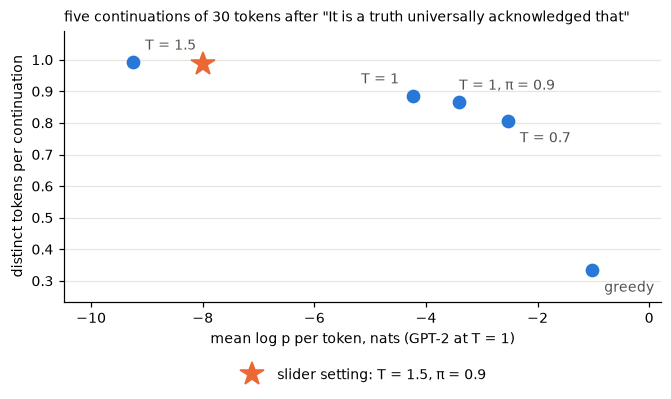

greedy           mean log p  -1.024   distinct share 0.333
T = 0.7          mean log p  -2.536   distinct share 0.807
T = 1            mean log p  -4.231   distinct share 0.887
T = 1.5          mean log p  -9.250   distinct share 0.993
T = 1, π = 0.9   mean log p  -3.407   distinct share 0.867
slider setting   mean log p  -7.987   distinct share 0.987


In [26]:
show_tradeoff(AUSTEN, T=1.5, pi=0.9)  # T > 0: five random draws of one prompt

In [27]:
explore(show_tradeoff, prompt=prompt_box(AUSTEN), T=slider(0.0, 2.0, 0.1, 0.0),
        pi=slider(0.05, 1.0, 0.05, 1.0), draw=slider(0, 9, 1, 0))

<details><summary><b>Answer</b></summary>

By mean log-probability per token: greedy ($-1.02$), $T = 0.7$ ($-2.54$), $T = 1$ ($-4.23$), $T = 1.5$ ($-9.25$). By share of distinct tokens per continuation, the order is reversed: 0.33 (10 distinct tokens in 30), 0.81, 0.89, 0.99. Top-p $\pi = 0.9$ at $T = 1$ gives $-3.41$ and 0.87, between $T = 0.7$ and $T = 1$ on both measures; at one step, the expected log-probability is $-5.76$ nats after the truncation, against $-6.38$ before. The star, $T = 1.5$ with $\pi = 0.9$, gives $-7.99$ and 0.99: at $T = 1.5$ the nucleus after the Austen prompt has 15,670 tokens (section 5), and the text is close to that of $T = 1.5$ alone.

</details>

## 10. Ten Formulas

| rule | formula | property |
|---|---|---|
| sentence | $\log P = \sum_t \log p(w_t \mid c, w_{<t})$ | surprise in bits adds up over tokens |
| temperature | $p^{(T)}_i \propto e^{z_i/T}$ | ranking fixed; $T \to 0$: greedy; $T \to \infty$: uniform |
| entropy | $dH/dT = \mathrm{Var}_{p^{(T)}}(z)/T^3$ | $H$ grows with $T$ |
| truncation | $\mathrm{KL}(q \parallel p) = -\log M$, $\mathrm{TV} = 1 - M$ | only the cut mass enters; relative to the truncated $p^{(T)}$ |
| top-k | $S_k$ = the $k$ largest $p_i$ | same set at every $T$; $\mathrm{KL} \le \log(\lvert V \rvert / k)$ |
| top-p | $k^*(\pi) = \min\{k : \sum_{j \le k} p_{(j)} \ge \pi\}$ | $\mathrm{KL} \le -\log \pi$; $k^*$ grows with $T$ |
| min-p | $p_i \ge p_{\text{base}}\, p_{\max}$, i.e. $z_i \ge z_{\max} + T \log p_{\text{base}}$ | $\lvert S \rvert \le 1 + (1 - p_{\max})/(p_{\text{base}}\, p_{\max})$ |
| repetition penalty | $z_i' = z_i/\theta$ or $\theta z_i$ on repeated tokens | repeated mass falls; depends on the offset of $z$ |
| beam search | keep the $B$ largest $\log P$ | $B = 1$ is greedy; finished beams ranked by $\log P / n^{\alpha}$ |
| expected log-probability | $g(T) = \mathbb{E}_{p^{(T)}}[\log p]$, $dg/dT = -\mathrm{Var}_{p^{(T)}}(z)/T^2$ | $g(1) = -H(p)$; higher after a truncation |